# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Zilionis 2019's NSCLC malignant manifold is **non-branching**: the developmental signatures lie
on a **single dominant axis** — gastrulation (Gast) high at one pole opposed to posterior
somitogenesis (pSom) at the other — rather than a hub where Gast+pSom *co-express* and diverge
into two arms. The decisive test is the **co-expression enrichment**: a Puram-style hub shows
Gast&pSom joint-high enrichment > 1 (the programmes cooperate at the branch point); here it is
**0.73 < 1** — Gast and pSom are *mutually exclusive*, so the strong Gast↔pSom anti-correlation
(smoothed r ≈ −0.53, near Puram's −0.49 anchor) is the *two ends of one axis*, not a bifurcation.
A PPT *tree* over this cloud throws 3–5 spurious forks (200 nodes spidering a continuous 3.9k-cell
blob; fork count unstable across λ), whereas an ElPiGraph **principal curve** (non-branching by
construction) is clean and **fold-free** (2 tips, 0 forks, self-approach > 2 across node counts).
The correct topology is therefore a principal curve fit on the *joint* embedding — **not** a
re-embedding (re-embedding an anisotropic compartment fabricates folds; the Kürten §4 failure).

**Scope decision (derived, not inherited).** The manifold splits into two density lobes, but the
split is **not proliferative** (both lobes low-cycling, 2.5% / 7.7%; overall 6.4%), **not
histological** (both carry LUAD+LUSC), and **not one patient** (all 6 samples in each) — so the
Kürten/Lin cell-cycle confound is absent and the **whole manifold** is kept (Qian/Sun/Lee/Steele
no-scoping precedent). The curve is rooted at the **Gast-high tip** (gastrulation is the earliest
embryonic programme) and pseudotime flows to the somitogenesis-high terminus. Deliverable:
`manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_out, exist_ok=True)

### Load processed manifold and score developmental modules
Keep all cells on their *original joint embedding coordinates* — no re-embedding. Re-score the
three embryonic signatures against the shared **union** control pool and graph-smooth to read
geography rather than inDrop per-cell dropout.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
u,s,vt = np.linalg.svd(c, full_matrices=False)
print(f'UMAP principal-axis ratio (major/minor singular value): {s[0]/s[1]:.2f}')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('raw module means (honest readout):', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

whole malignant manifold: 3920 cells on the joint embedding
UMAP principal-axis ratio (major/minor singular value): 1.09
Gast: 79/81 genes present
pSom: 95/98 genes present
Crest: 104/104 genes present
raw module means (honest readout): {'Gast': -0.0092, 'pSom': 0.0386, 'Crest': -0.0225}


### Topology — hub co-expression test vs single-axis, and tree-vs-curve
The Puram branching signature is a Gast+pSom **co-expression hub** (joint-high enrichment > 1)
that diverges into arms with Crest terminal. We test all three module pairs for co-expression
enrichment and count forks under a PPT tree vs an ElPiGraph curve.

In [4]:
def enrich(m1,m2):
    z1=(adata.obs[m1]-adata.obs[m1].mean())/adata.obs[m1].std()
    z2=(adata.obs[m2]-adata.obs[m2].mean())/adata.obs[m2].std()
    j=((z1>0.5)&(z2>0.5)).mean(); e=(z1>0.5).mean()*(z2>0.5).mean()
    return j/e if e>0 else np.nan
print('co-expression enrichment (>1 = hub/co-express, <1 = mutually exclusive):')
for x,y in [('Gast','pSom'),('Gast','Crest'),('pSom','Crest')]:
    print(f'  {x}&{y}-high: {enrich(x,y):.2f}')
print('smoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r=np.corrcoef(adata.obs[a],adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
# PPT tree fork scan (spurious over a continuous cloud)
def tree_forks(Nn,lam):
    aa=adata.copy()
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        scf.tl.tree(aa,method='ppt',Nodes=Nn,ppt_lambda=lam,ppt_sigma=.5,use_rep='X_umap',seed=SEED,plot=False)
    B=np.asarray(aa.uns['graph']['B'])
    return int(((B>0).sum(0)==1).sum()), int(((B>0).sum(0)>=3).sum())
print('PPT tree fork scan (unstable spurious forks = continuous cloud, not a bifurcation):')
for Nn,lam in [(150,2000),(200,2000),(200,4000)]:
    t,f=tree_forks(Nn,lam); print(f'  N={Nn} lam={lam}: {t} tips, {f} forks')

co-expression enrichment (>1 = hub/co-express, <1 = mutually exclusive):
  Gast&pSom-high: 0.73
  Gast&Crest-high: 0.40
  pSom&Crest-high: 0.37
smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = -0.53
  Crest_sm vs Gast_sm: r = -0.51
  Crest_sm vs pSom_sm: r = -0.36
PPT tree fork scan (unstable spurious forks = continuous cloud, not a bifurcation):
  N=150 lam=2000: 7 tips, 5 forks
  N=200 lam=2000: 4 tips, 2 forks
  N=200 lam=4000: 4 tips, 2 forks


### Scope decision — whole manifold vs one lobe (cell-cycle confound test)
The two lobes are not a proliferative split (both low-cycling) — we confirm directly: (i) the
developmental gene sets are essentially **cell-cycle-free** (overlap with the Regev–Tirosh S+G2M
programme); (ii) the Gast↔pSom anti-correlation **survives within non-cycling cells alone**;
(iii) pseudotime does not co-vary with cycling. So the axis is developmental, not proliferative —
keep the **whole manifold**.

In [5]:
s_genes=set(('MCM5 PCNA TYMS FEN1 MCM2 MCM4 RRM1 UNG GINS2 MCM6 CDCA7 DTL PRIM1 UHRF1 HELLS RFC2 RPA2 '
 'NASP RAD51AP1 GMNN WDR76 SLBP CCNE2 UBR7 POLD3 MSH2 ATAD2 RAD51 RRM2 CDC45 CDC6 EXO1 TIPIN DSCC1 '
 'BLM CASP8AP2 USP1 CLSPN POLA1 CHAF1B BRIP1 E2F8').split())
g2m_genes=set(('HMGB2 CDK1 NUSAP1 UBE2C BIRC5 TPX2 TOP2A NDC80 CKS2 NUF2 CKS1B MKI67 TMPO CENPF TACC3 '
 'FAM64A SMC4 CCNB2 CKAP2L CKAP2 AURKB BUB1 KIF11 ANP32E TUBB4B GTSE1 KIF20B HJURP CDCA3 HN1 CDC20 TTK '
 'CDC25C KIF2C RANGAP1 NCAPD2 DLGAP5 CDCA2 CDCA8 ECT2 KIF23 HMMR AURKA PSRC1 ANLN LBR CKAP5 CENPE CTCF '
 'NEK2 G2E3 GAS2L3 CBX5 CENPA').split())
cc=s_genes|g2m_genes
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    ov=set(feat[src])&cc; print(f'  {lab}: {len(ov)}/{len(set(feat[src]))} genes overlap the cell-cycle programme')
noncyc=~adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
r_all=np.corrcoef(adata.obs['Gast_sm'],adata.obs['pSom_sm'])[0,1]
r_nc=np.corrcoef(adata.obs.loc[noncyc.values,'Gast_sm'],adata.obs.loc[noncyc.values,'pSom_sm'])[0,1]
print(f'  Gast<->pSom smoothed: all r={r_all:+.2f} | non-cycling only r={r_nc:+.2f} ({int(noncyc.sum())} cells)')
print('per-lobe smoothed developmental means:')
print(adata.obs.groupby('compartment', observed=True)[['Gast_sm','pSom_sm','Crest_sm']].mean().round(4).to_string())
print('-> developmental axis is cell-cycle-free and survives without cycling cells; keep whole manifold (no scoping).')
sub = adata

  Gast: 0/81 genes overlap the cell-cycle programme
  pSom: 2/98 genes overlap the cell-cycle programme
  Crest: 0/104 genes overlap the cell-cycle programme
  Gast<->pSom smoothed: all r=-0.53 | non-cycling only r=-0.53 (3671 cells)
per-lobe smoothed developmental means:
              Gast_sm  pSom_sm  Crest_sm
compartment                             
Gast-leaning  -0.0012   0.0360   -0.0253
pSom-leaning  -0.0211   0.0436   -0.0191
-> developmental axis is cell-cycle-free and survives without cycling cells; keep whole manifold (no scoping).


### Fit the principal curve (ElPiGraph)
`Nodes / epg_lambda / epg_mu` give a **fold-free** monotone backbone: a node self-approach ratio
> 1 (minimum distance between graph-non-adjacent nodes, in units of median edge length) certifies
the curve does not fold back on itself. `epg_mu=100` is strong bending regularisation. Fold-freeness
and the 2-tip / 0-fork topology are stable across Nodes = 15/20/30.

In [6]:
def fold_diag(ad):
    B=np.asarray(ad.uns['graph']['B']); F=ad.uns['graph']['F'].T
    G=shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj=np.where(np.triu(B>0)); med=np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin=np.inf
    for a in range(F.shape[0]):
        for b in range(a+1,F.shape[0]):
            if G[a,b]>=3: dmin=min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips=int(((B>0).sum(0)==1).sum()); forks=int(((B>0).sum(0)>=3).sum())
    return dmin/med, tips, forks
for Nn in [15,20,30]:
    a2=sub.copy()
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        scf.tl.curve(a2, Nodes=Nn, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa,tips,forks=fold_diag(a2); print(f'curve N={Nn}: {tips} tips, {forks} forks | self-approach {sa:.2f}')
with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa,tips,forks=fold_diag(sub)
print(f'chosen curve N=20: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks==0 and sa>1, 'topology check failed'

curve N=15: 2 tips, 0 forks | self-approach 2.84
curve N=20: 2 tips, 0 forks | self-approach 2.45
curve N=30: 2 tips, 0 forks | self-approach 2.15
chosen curve N=20: 2 tips, 0 forks | fold self-approach ratio = 2.45 (>1 = fold-free)


### Derive the root (data-driven)
The root is the curve tip where Gast is highest and pSom lowest — the developmental origin
(gastrulation, the earliest embryonic programme). Pseudotime then flows to the somitogenesis-high
terminus.

In [7]:
B=np.asarray(sub.uns['graph']['B']); tps=np.where((B>0).sum(0)==1)[0]
R=np.asarray(sub.obsm['X_R']); hard=R.argmax(1)
D=shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info={}
for tp in tps:
    m=np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp]=(sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root=int(max(tps, key=lambda tp: info[tp][0]-info[tp][1]))   # Gast-high, pSom-low origin
print('derived root = tip', root, '(Gast-high, pSom-low developmental origin)')
with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t=sub.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed):')
for s_ in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p=spearmanr(t, sub.obs[s_]); print(f'  {s_}: rho={rho:+.3f} p={p:.1e}')
tn=(t-t.min())/(t.max()-t.min())
for m,lab_ in [('Gast_sm','Gastrulation'),('pSom_sm','Somitogenesis'),('Crest_sm','Neural-crest')]:
    hi=sub.obs[m]>=sub.obs[m].quantile(0.9)
    print(f'{lab_}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')
g2m=pd.to_numeric(sub.obs.get('g2m_score', pd.Series(0,index=sub.obs.index)), errors='coerce').fillna(0).values
g1s=pd.to_numeric(sub.obs.get('g1s_score', pd.Series(0,index=sub.obs.index)), errors='coerce').fillna(0).values
rho_c,_=spearmanr(t, np.maximum(g1s,g2m)); print(f'caveat: pseudotime vs cycling score rho = {rho_c:+.2f} (confound absent if ~0)')

tip 0: Gast=-0.0214 pSom=+0.0440 Crest=-0.0194
tip 2: Gast=-0.0007 pSom=+0.0312 Crest=-0.0211
derived root = tip 2 (Gast-high, pSom-low developmental origin)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.583 p=0.0e+00
  pSom_sm: rho=+0.767 p=0.0e+00
  Crest_sm: rho=+0.007 p=6.6e-01
Gastrulation-high decile mean pseudotime = 0.15
Somitogenesis-high decile mean pseudotime = 0.99
Neural-crest-high decile mean pseudotime = 0.55
caveat: pseudotime vs cycling score rho = -0.03 (confound absent if ~0)


### House orientation (re-used from 01, verified against pseudotime)
The house orientation — a single rigid rotation of the diagonal developmental axis to horizontal
— was derived **once in 01** (rotation angle = manifold's axis of maximal variance; sign places
the Gast-high origin on the left) and stored as `X_umap_lin`. Every UMAP across 01–04 re-uses
these exact coordinates. Here we **verify**: corr(`X_umap_lin` x-axis, pseudotime) must be
strongly positive (low pseudotime = developmental origin on the left).

In [8]:
t=sub.obs['t'].values
r=float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])
c=sub.obsm['X_umap']-sub.obsm['X_umap'].mean(0)
dirv=np.array([np.cov(c[:,0],t)[0,1], np.cov(c[:,1],t)[0,1]])
_,_,vt=np.linalg.svd(c, full_matrices=False)
dang=abs(np.degrees(np.arctan2(dirv[1],dirv[0]) - np.arctan2(vt[0,1],vt[0,0]))) % 180
dang=min(dang,180-dang)
assert r>0.5, f'stored orientation not pseudotime-consistent (corr={r:.2f})'
print(f'house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = {r:+.2f}')
print(f'variance-axis vs pseudotime-axis disagreement = {dang:.1f}deg (small -> equivalent orientation)')

house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = +0.85
variance-axis vs pseudotime-axis disagreement = 15.4deg (small -> equivalent orientation)


### Save manifold + trajectory figure (deliverable)
House style `(3.5,1.5)`, pseudotime left→right on `X_umap_lin`, `size=30`, cividis.

saved manifold.h5ad + manifold.pdf


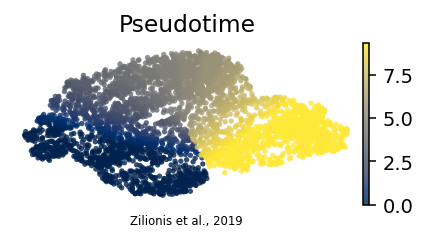

In [9]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl=sub.obsm['X_umap_lin']
xlo,xhi=np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi=np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot=sub.copy(); plot.obsm['X_umap']=plot.obsm['X_umap_lin']
fig,ax=plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Zilionis et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
plt.show()
print('saved manifold.h5ad + manifold.pdf')